# T03 – Loudness & timbre: first year vs. 2023
*MIR & ML for Audio · TU Berlin · WiSe 2026/27*

| | |
|---|---|
| **Name** | Hallvard Jensen |
| **Student ID** | 0549158 |
| **Corpus (genre)** | Nu Disco/Disco |

**Submission:** work in this notebook – code, figures and text answers all stay here. Before uploading: **Restart Kernel & Run All**, check that every output is shown, then upload this `.ipynb` file.

**Documentation:** document your work directly in the notebook – comments in your code cells and, where helpful, short markdown cells.

### Sources & AI tools
- **Sources** (literature, data, code):
  - stackoverflow.com
  - librosa documentation
  - Lecture slides
  - scikit-learn.org
- **LLM coding assistants** (tool/model – how and what for):
  - Claude has been used to understand library features and debug written code

## Tasks
1. How has loudness changed between the Top 100 tracks of the first year of your time series and those of 2023?
   - Compute LUFS, loudness range, sample peak, RMS and crest factor based on the previews
   - Compare the central tendency of these measures between both years for this EDMC genre using suitable significance test(s)
   - Summarise the results of the comparison in one sentence a layperson can understand
2. How has timbre changed between the Top 100 tracks of the first year of your time series and those of 2023?
   - Create meaningful categorical timbre profiles based on the previews (clustering method of your choice)
   - Interpret the timbre profiles you created by giving them suitable names
   - Compare the relative dominance of the timbre profiles between both years in this EDMC genre
   - Summarise the results of the comparison in one sentence a layperson can understand

---
## Setup

Expensive steps (feature extraction, separation, model training): save the results to `OUTPUT_DIR` (e.g. as CSV) and load them on the next run instead of recomputing – *Run All* stays fast. Results of earlier sessions are in `output/T02/`, `output/T03/`, …

In [1]:
# import standard packages you'll need

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(sys.executable)

# ─ add your own additional imports here:
import librosa
import pyloudnorm as pyln
import tqdm
import scipy
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

/home/hallvard/miniforge3/envs/mirml/bin/python


In [2]:
# ── CONFIG ───────────────────────────────────────────────────────────────
CORPUS_DIR = Path("data") / "nu-disco-disco"   # ← name of your corpus folder
# ─────────────────────────────────────────────────────────────────────────
SESSION = "T03"
PREVIEW_DIR = CORPUS_DIR / "previews"
OUTPUT_DIR = Path("output") / SESSION      # results of this session
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert CORPUS_DIR.is_dir(), f"Not found: {CORPUS_DIR.resolve()} → check CORPUS_DIR"
CHART_CSV = next(CORPUS_DIR.glob("*.csv"))
print(CHART_CSV)


data/nu-disco-disco/Nu_Disco_Disco.csv


---
## Task 1
**How has loudness changed between the Top 100 tracks of the first year of your time series and those of 2023?**

### 1.1 · Compute LUFS, loudness range, sample peak, RMS and crest factor based on the previews

In [3]:
# 1.1
def prefix_file(task: str, filename: str) -> str:
    return f"t02_{task}_nu_disco_disco_0549158_{filename}"


def get_loudness_features(id: int):
    """
    Returns a dictionary of loudness features calculated on the preview
    mp3 file corresponding to the provided ID.

    :param id:  ID of preview file
    """
    path = PREVIEW_DIR / f"{id}.mp3"
    if not path.exists():
        return {}
    y, sr = librosa.load(path, sr=22050)

    # Make sure all previews are mono
    assert y.ndim == 1

    # Compute RMS for entire track
    rms = np.sqrt(np.mean(np.pow(y, 2)))
    peak = np.max(np.abs(y))

    # Keep all units consistent (dB)
    rms_db = 20 * np.log10(rms)
    peak_db = 20 * np.log10(peak)
    meter = pyln.Meter(sr)

    return {
        "rms": rms_db,
        "lufs": meter.integrated_loudness(y),
        "lra": meter.loudness_range(y),
        "sample_peak": peak_db,
        "crest_factor": peak_db - rms_db,
    }


df_clusters = pd.read_csv(CHART_CSV)

# Select only top 100 tracks from 2019 and 2023
mask = (df_clusters["rank"] <= 100) & (df_clusters["year"].isin([2019, 2023]))
df100 = df_clusters[mask].copy()

# Calculate loudness features for each track. Make sure to compute only
# for unique track ids to avoid doing repeat calculations
df_ids = df100["beatport_track_id"].drop_duplicates()
loud_feat = [get_loudness_features(id) for id in tqdm.tqdm(df_ids)]
df_loud = pd.DataFrame(loud_feat, index=df_ids.index)

# Assign track ids to enable merge of data frames
df_loud["beatport_track_id"] = df_ids

# Merge loudness features with top 100 tracks on track id and save
df_merge = df100.merge(df_loud, on="beatport_track_id")
LOUDNESS_CSV = OUTPUT_DIR / prefix_file("1.1", "loudness.csv")
df_merge.to_csv(LOUDNESS_CSV, index=False)

  0%|          | 0/192 [00:00<?, ?it/s]/home/hallvard/miniforge3/envs/mirml/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 192/192 [03:16<00:00,  1.02s/it]


### 1.2 · Compare the central tendency of these measures between both years for this EDMC genre using suitable significance test(s)

In [4]:
# 1.2
df_clusters = pd.read_csv(LOUDNESS_CSV)

# Remove any duplicate track ids within the same year
df_clusters = df_clusters.drop_duplicates(["beatport_track_id", "year"])

# Iterate over each loudness feature and perform the Welch t-test
cols = ["rms", "lufs", "lra", "sample_peak", "crest_factor"]
rows = []
for col in cols:
    a = df_clusters.loc[df_clusters["year"] == 2019, col].dropna()
    b = df_clusters.loc[df_clusters["year"] == 2023, col].dropna()

    res = scipy.stats.ttest_ind(a, b, equal_var=False)  # Welch t-test
    conf = res.confidence_interval()
    rows.append(
        {
            "feature": col,
            "p_value": res.pvalue,
            "statistic": res.statistic,
            "conf_low": conf.low,
            "conf_high": conf.high,
        }
    )

res = pd.DataFrame(rows)
print("Welch t-test (2019 vs. 2023):")
print(res)

Welch t-test (2019 vs. 2023):
        feature   p_value  statistic  conf_low  conf_high
0           rms  0.019573  -2.356583 -1.091659  -0.096472
1          lufs  0.008515  -2.661806 -1.034312  -0.153468
2           lra  0.462945  -0.735659 -1.087106   0.496800
3   sample_peak  0.642213   0.465459 -0.189735   0.306791
4  crest_factor  0.002069   3.127575  0.240743   1.064445


### 1.3 · Summarise the results of the comparison in one sentence a layperson can understand

#### Answer 1.3

The top 100 tracks from 2023 are slightly louder and more compressed than top 100 from 2019, but it is barely noticeable and not strong enough to be conclusive.

---
## Task 2
**How has timbre changed between the Top 100 tracks of the first year of your time series and those of 2023?**

### 2.1 · Create meaningful categorical timbre profiles based on the previews (clustering method of your choice)

In [5]:
# 2.1
def get_spectral_features(id: int):
    """
    Returns a dictionary of spectral features calculated on the preview
    mp3 file corresponding to the provided ID.

    :param id:  ID of preview file
    """
    path = PREVIEW_DIR / f"{id}.mp3"
    if not path.exists():
        return {}
    y, sr = librosa.load(path, sr=22050)

    # Make sure all previews are mono
    assert y.ndim == 1

    # Create all spectral features
    mean_sc = librosa.feature.spectral_centroid(y=y, sr=sr).mean()
    mean_sf = librosa.feature.spectral_flatness(y=y).mean()
    mean_bw = librosa.feature.spectral_bandwidth(y=y, sr=sr).mean()
    mean_ro = librosa.feature.spectral_rolloff(y=y, sr=sr).mean()

    return {
        "spectral_centroid": mean_sc,
        "spectral_flatness": mean_sf,
        "spectral_bandwidth": mean_bw,
        "spectral_rolloff": mean_ro,
    }


# Calculate spectral features for each track
timb_feat = [get_spectral_features(id) for id in tqdm.tqdm(df_ids)]
df_timb = pd.DataFrame(timb_feat, index=df_ids.index)

# Assign track ids to enable merge of data frames
df_timb["beatport_track_id"] = df_ids

# Merge loudness features with top 100 tracks on track id and save
df_timb = df100.merge(df_timb, on="beatport_track_id")
SPECTRAL_CSV = OUTPUT_DIR / prefix_file("2.1", "spectral.csv")
df_timb.to_csv(SPECTRAL_CSV, index=False)

100%|██████████| 192/192 [05:55<00:00,  1.85s/it]


In [6]:
# Pick out the feature columns we want to look at
df_clusters = pd.read_csv(SPECTRAL_CSV)
feat_cols = [
    "spectral_centroid",
    "spectral_flatness",
    "spectral_bandwidth",
    "spectral_rolloff",
]

df_clusters["spectral_flatness"] = np.log10(df_clusters["spectral_flatness"])
tracks = (
    df_clusters.drop_duplicates("beatport_track_id")
    .dropna(subset=feat_cols)
    .copy()
)

# Preprocessing data: centering and orthogonalization
X = StandardScaler().fit_transform(tracks[feat_cols])
Z = PCA(n_components=0.95, whiten=True, random_state=0).fit_transform(X)

# Check which value for K gives the smallest BIC value
for k in range(2, 9):
    gmm = GaussianMixture(k, n_init=10, random_state=0).fit(Z)
    print(f"k: {k}, bic: {gmm.bic(Z)}")

# Previous runs showed that k=2 has lowest BIC, thus becomes our selection.
K = 2

# Train model
gmm = GaussianMixture(K, n_init=10, random_state=0).fit(Z)
tracks["profile"] = gmm.predict(Z)

# Print results to determine profiles
z = pd.DataFrame(X, columns=feat_cols, index=tracks.index)
z["profile"] = tracks["profile"]
print(z.groupby("profile").mean().round(2).to_string())

print("Number of tracks per profile:")
print(tracks["profile"].value_counts().to_string())

df_clusters = df_clusters.merge(
    tracks[["beatport_track_id", "profile"]], on="beatport_track_id"
)
SPECTRAL_CLUSTERS = OUTPUT_DIR / prefix_file("2.1", "spectral_clusters.csv")
df_clusters.to_csv(SPECTRAL_CLUSTERS, index=False)

k: 2, bic: 998.4062362973724
k: 3, bic: 1019.5488066585087
k: 4, bic: 1043.96451469073
k: 5, bic: 1062.1846613709035
k: 6, bic: 1084.7270745112257
k: 7, bic: 1101.3929284837557
k: 8, bic: 1121.885419225797
         spectral_centroid  spectral_flatness  spectral_bandwidth  spectral_rolloff
profile                                                                            
0                     0.61               0.37                0.83              0.76
1                    -0.55              -0.34               -0.75             -0.68
Number of tracks per profile:
profile
1    88
0    79


### 2.2 · Interpret the timbre profiles you created by giving them suitable names

#### Answer 2.2

We chose 2 profiles in 2.1 since this selection had the best BIC value (lowest). We have three features that really describe much of the same and thus move together: centroid, bandwidth, and rolloff. This means that profile 0 is generally brighter than profile 1. The flatness describes noisiness, and profile 0 is more noisy. Thus we get:

- Profile 0: Bright/noisy
- Profile 1: Dark/tonal

### 2.3 · Compare the relative dominance of the timbre profiles between both years in this EDMC genre

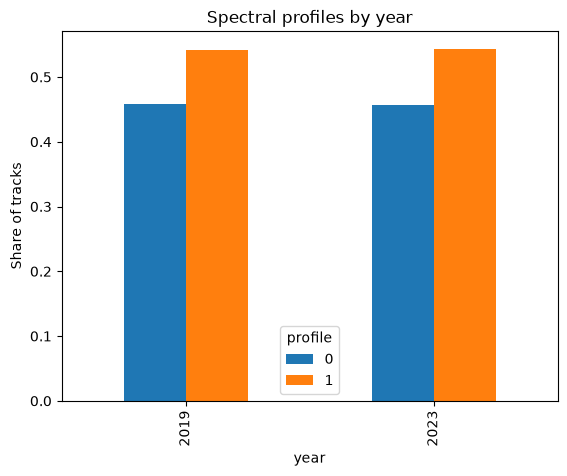

In [7]:
# 2.3
df = pd.read_csv(SPECTRAL_CLUSTERS)
ax = pd.crosstab(df["year"], df["profile"], normalize="index").plot(kind="bar")
ax.set_ylabel("Share of tracks")
ax.set_title("Spectral profiles by year")
ax.figure.savefig(OUTPUT_DIR / prefix_file("2.3", "spectral_profiles.png"))
plt.show()

### 2.4 · Summarise the results of the comparison in one sentence a layperson can understand

#### Answer 2.4

From the figure we see that the fraction of bright and noisy tracks compared to dark and tonal tracks have not really changed between 2019 and 2023, with dark and tonal still being the dominating profile.

---
## Before you upload
- [ ] Name, student ID and genre filled in
- [ ] **Restart Kernel & Run All** runs without errors, all outputs visible
- [ ] Figures labelled (axes, units, title); audio examples embedded where asked